## Importation des bibliothèques


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

df_clean = pd.read_csv('df_clean.csv', nrows=500000)

print(df_clean.head())

                 product_name department          aisle  order_id  \
0  Chocolate Sandwich Cookies     snacks  cookies cakes     23202   
1  Chocolate Sandwich Cookies     snacks  cookies cakes     24367   
2  Chocolate Sandwich Cookies     snacks  cookies cakes     24760   
3  Chocolate Sandwich Cookies     snacks  cookies cakes     25365   
4  Chocolate Sandwich Cookies     snacks  cookies cakes     26490   

   add_to_cart_order  reordered   user_id  order_dow  order_hour_of_day  \
0                3.0        0.0  162394.0        3.0               12.0   
1                2.0        1.0  148255.0        6.0               17.0   
2                5.0        1.0  205157.0        5.0               17.0   
3                9.0        1.0  181127.0        3.0               20.0   
4               14.0        1.0   92648.0        5.0               15.0   

   days_since_prior_order  
0                     7.0  
1                     6.0  
2                    25.0  
3                    3

## 🛒 Les bases du panier


## Quels sont les produits les plus vendus ?

/tmp/ipykernel_7218/3212420787.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=best_products.values, y=best_products.index, palette='viridis')


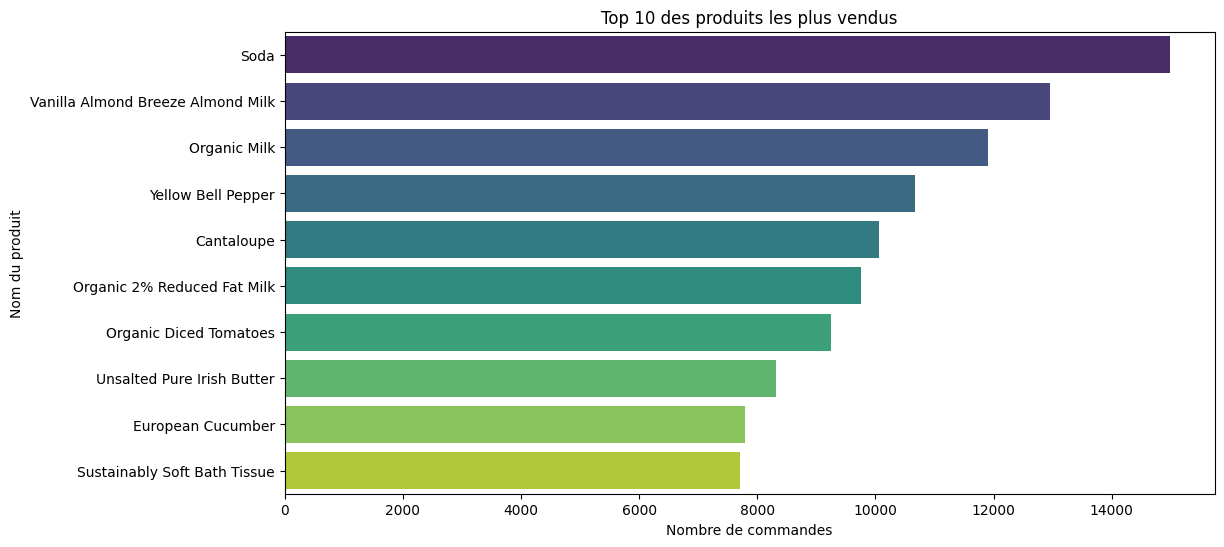

In [20]:
best_products = df_clean['product_name'].value_counts().head(10)

plt.figure(figsize=(12, 6))
sns.barplot(x=best_products.values, y=best_products.index, palette='viridis')
plt.title('Top 10 des produits les plus vendus')
plt.xlabel('Nombre de commandes')
plt.ylabel('Nom du produit')
plt.show()

    L'analyse

Le graphique montre les 10 produits les plus vendus et on observe que le Soda est de loin le produit le plus commandé. Les boissons semblent très populaires puisque plusieurs types de lait apparaissent aussi dans le classement (Vanilla Almond Breeze Almond Milk, Organic Milk et Organic 2% Reduced Fat Milk). On remarque également une forte présence de produits frais comme le poivron jaune, le cantaloup et le concombre européen. Cela indique que les clients achètent à la fois des boissons et des produits alimentaires frais de manière régulière.


    réponse business

D’un point de vue business, l’entreprise devrait prioriser la disponibilité et la mise en avant des produits les plus vendus, en particulier le soda et les différents types de lait. Ces produits peuvent être utilisés pour créer des promotions ou des ventes croisées (par exemple avec des snacks ou d’autres produits frais). En parallèle, la présence de fruits et légumes dans le top montre qu’il existe une demande importante pour les produits frais, ce qui pourrait encourager l’entreprise à renforcer cette catégorie et optimiser les stocks pour éviter les ruptures.

## Quel article les clients mettent-ils en premier dans leur panier ?


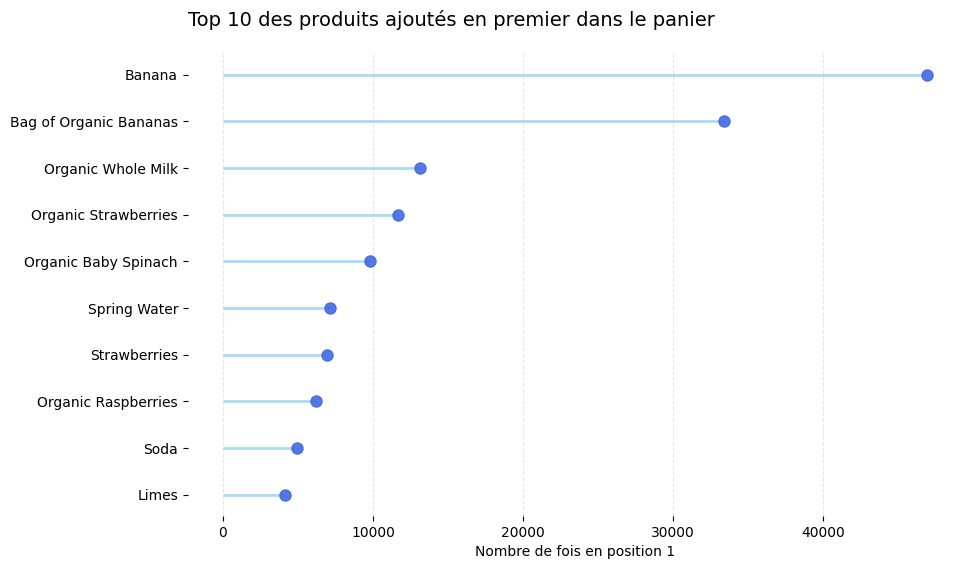

In [21]:
df = pd.read_csv('df_clean.csv')

# Identification des produits ajoutés en premier
first_added = df[df['add_to_cart_order'] == 1]

# Comptage des 10 produits les plus fréquents
top_first_products = first_added['product_name'].value_counts().head(10).reset_index()
top_first_products.columns = ['product_name', 'count']

# Visualisation
plt.figure(figsize=(10, 6))
top_first_products = top_first_products.sort_values(by='count', ascending=True)

plt.hlines(y=top_first_products['product_name'], xmin=0, xmax=top_first_products['count'], 
           color='skyblue', alpha=0.7, linewidth=2)
plt.plot(top_first_products['count'], top_first_products['product_name'], "o", 
         markersize=8, color='royalblue', alpha=0.9)

plt.title('Top 10 des produits ajoutés en premier dans le panier', loc='left', fontsize=14, pad=20)
plt.xlabel('Nombre de fois en position 1')
plt.ylabel('')
sns.despine(left=True, bottom=True) 
plt.grid(axis='x', linestyle='--', alpha=0.3)

plt.show()

    analyse

Le graphique montre les 10 produits que les clients ajoutent le plus souvent en premier dans leur panier. On voit clairement que la banane est le produit le plus fréquemment ajouté en premier, suivie par le sac de bananes bio. Ensuite on retrouve surtout des produits frais et sains comme le lait bio, les fraises bio, les épinards bio ou encore les framboises. Cela indique que les clients commencent souvent leurs achats par des produits de base ou des fruits et légumes.

    réponse business

D’un point de vue business, cela signifie que certains produits jouent un rôle de produit d’entrée dans le panier. Les fruits comme les bananes peuvent servir de produits d’appel pour inciter les clients à commencer leurs achats. L’entreprise pourrait donc mettre en avant ces produits sur la page d’accueil ou dans des promotions afin d’encourager les clients à démarrer leur panier plus rapidement et potentiellement acheter d’autres produits ensuite.

## Quels sont les rayons qui ont le plus de produits ?


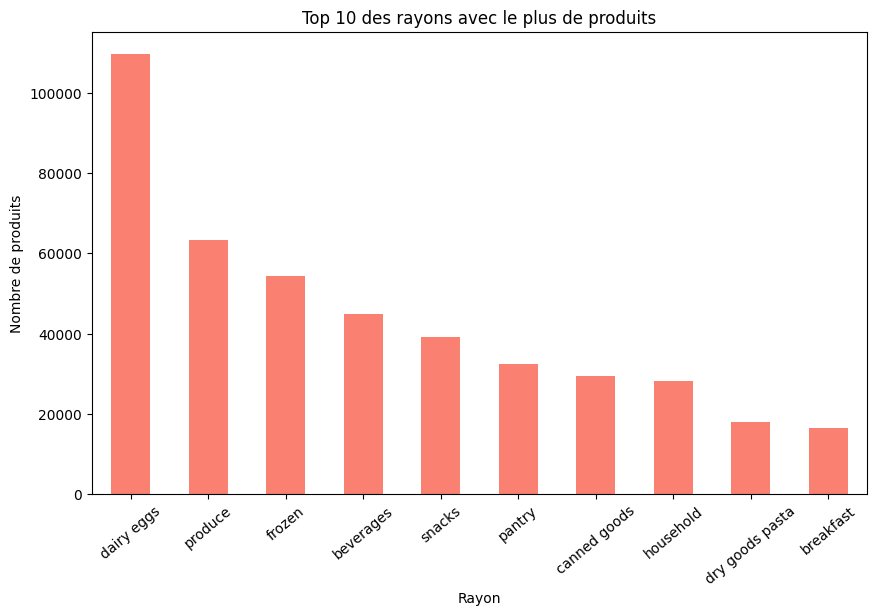

In [22]:
# Compte le nombre de produits par rayon
top_rayons = df_clean['department'].value_counts().head(10)

# Affiche le graphique en barre
plt.figure(figsize=(10, 6))
top_rayons.plot(kind='bar', color='salmon')
plt.title('Top 10 des rayons avec le plus de produits')
plt.xlabel('Rayon')
plt.ylabel('Nombre de produits')
plt.xticks(rotation=40) 
plt.show()

    analyse

Le graphique montre les rayons qui contiennent le plus de produits. On observe que le rayon dairy & eggs (produits laitiers et œufs) est celui qui possède le plus grand nombre de produits, très largement devant les autres. Ensuite viennent les rayons produce (fruits et légumes), frozen (produits surgelés) et beverages (boissons). Cela signifie que ces catégories représentent une grande partie de l’offre du magasin et regroupent beaucoup de références différentes.

     réponse business

D’un point de vue business, ces rayons sont stratégiques pour le magasin, car ils concentrent une grande variété de produits et répondent à des besoins quotidiens des clients. L’entreprise peut donc optimiser la gestion des stocks et la mise en avant dans ces catégories pour maximiser les ventes. Par exemple, proposer des promotions ou des recommandations dans les rayons les plus fournis peut aider les clients à découvrir plus de produits et augmenter le panier moyen.

## Quels sont les rayons qui ont le moins de produits ?


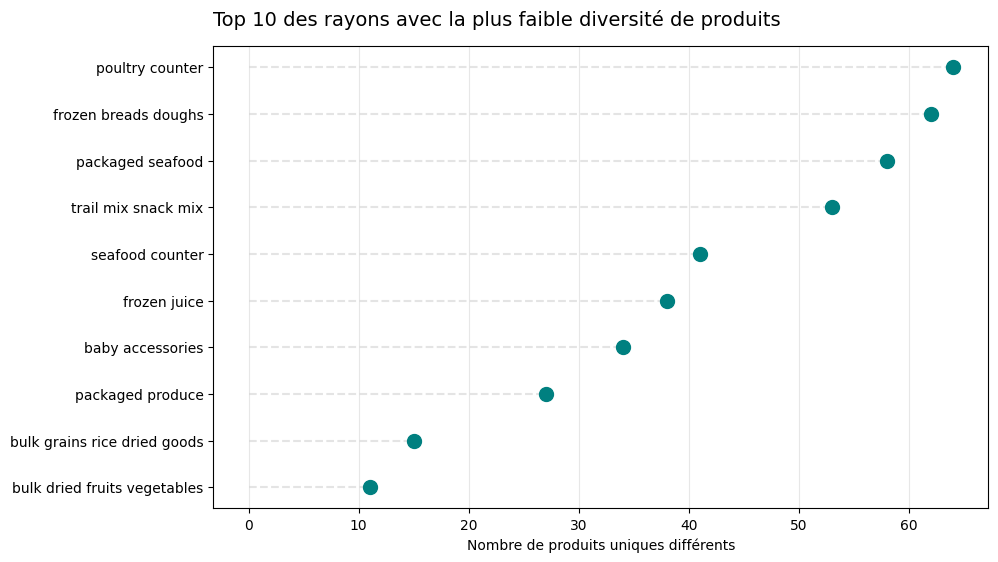

In [ ]:
df = pd.read_csv('df_clean.csv')

# Compte les produits uniques par rayon et prend les 10 plus petits
aisle_counts = df.groupby('aisle')['product_name'].nunique().nsmallest(10).reset_index()
aisle_counts.columns = ['Rayon', 'Nombre_de_Produits']

plt.figure(figsize=(10, 6))

# Trace les points
plt.scatter(aisle_counts['Nombre_de_Produits'], aisle_counts['Rayon'], 
            color='teal', s=100, zorder=3)

plt.hlines(y=aisle_counts['Rayon'], xmin=0, xmax=aisle_counts['Nombre_de_Produits'], 
           color='lightgray', linestyle='--', alpha=0.6, zorder=2)

plt.title('Top 10 des rayons avec la plus faible diversité de produits', loc='left', fontsize=14, pad=15)
plt.xlabel('Nombre de produits uniques différents')
plt.ylabel('')
plt.grid(axis='x', alpha=0.3)

plt.show()

    analyse

Le graphique montre les 10 rayons qui proposent le moins de choix, et on observe que les rayons de vente en vrac (bulk dried fruits vegetables et bulk grains rice dried goods) sont de loin ceux qui offrent la plus faible diversité, avec moins de 20 produits uniques différents. Les rayons très spécifiques ou de niche semblent également concernés, puisque des catégories comme les produits pré-emballés (packaged produce), les accessoires pour bébés (baby accessories) ou les jus surgelés (frozen juice) apparaissent dans le classement. Cela indique que pour certaines catégories, l'assortiment est très restreint et va directement à l'essentiel.

    réponse business

D’un point de vue business, l’entreprise devrait évaluer si cette faible diversité est un atout logistique ou une opportunité manquée. D'un côté, élargir la gamme des produits en vrac ("bulk") pourrait attirer davantage de clients soucieux de l'écologie (tendance du zéro déchet) et augmenter le panier moyen. De même, proposer plus de références pour les accessoires bébé pourrait mieux fidéliser les jeunes parents, une clientèle à forte valeur. En parallèle, si ces rayons génèrent peu de ventes globales, l'entreprise a tout intérêt à maintenir cette faible diversité pour optimiser les coûts d'inventaire et l'espace en magasin, en s'assurant simplement que les quelques produits proposés sont des incontournables.

## Quelle est la proportion de légumes bio dans les commandes ?


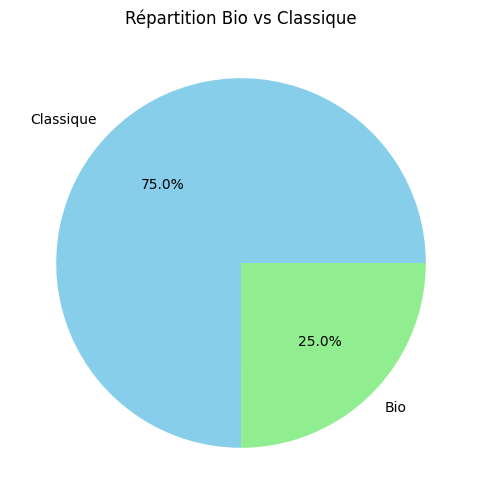

In [24]:
# Prépare les données
vegetables = df_clean[df_clean['department'] == 'produce'].copy()
# Créer une colonne avec des noms au lieu de True/False
vegetables['Type'] = vegetables['product_name'].str.contains('organic', case=False).map({True: 'Bio', False: 'Classique'})

#Affiche le graphique
plt.figure(figsize=(6, 6))
vegetables['Type'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['skyblue', 'lightgreen'])
plt.title('Répartition Bio vs Classique')
plt.ylabel('') 
plt.show()

    analyse

Le graphique en secteurs montre la proportion de légumes biologiques par rapport aux légumes classiques, et on observe que le segment Bio représente 25 % des commandes, tandis que le Classique domine avec 75 %. Cette répartition indique qu'un quart des clients privilégie déjà des options plus saines ou respectueuses de l'environnement pour leurs produits frais. Bien que le classique reste majoritaire, la part du bio est significative et montre une base de clients prête à payer pour de la qualité supérieure.


    réponse business

D’un point de vue business, l’entreprise devrait capitaliser sur cette niche de 25 % qui représente souvent une clientèle à plus haut revenu et plus fidèle. Il serait judicieux de mettre en place des campagnes de marketing ciblé pour ce segment "Bio-friendly" en leur proposant des produits complémentaires (comme l'épicerie fine ou les produits d'entretien écologiques). Par ailleurs, NEXTBUY pourrait envisager d'augmenter légèrement la diversité de l'offre bio pour voir si elle peut grignoter des parts de marché sur le conventionnel. Si la marge sur le bio est plus élevée, convertir seulement 5 % de clients supplémentaires vers ces produits pourrait augmenter considérablement la rentabilité globale du département "Produce".

## ⏰ Habitudes de consommation


## Quand les clients commandent-ils (jour/heure) ?


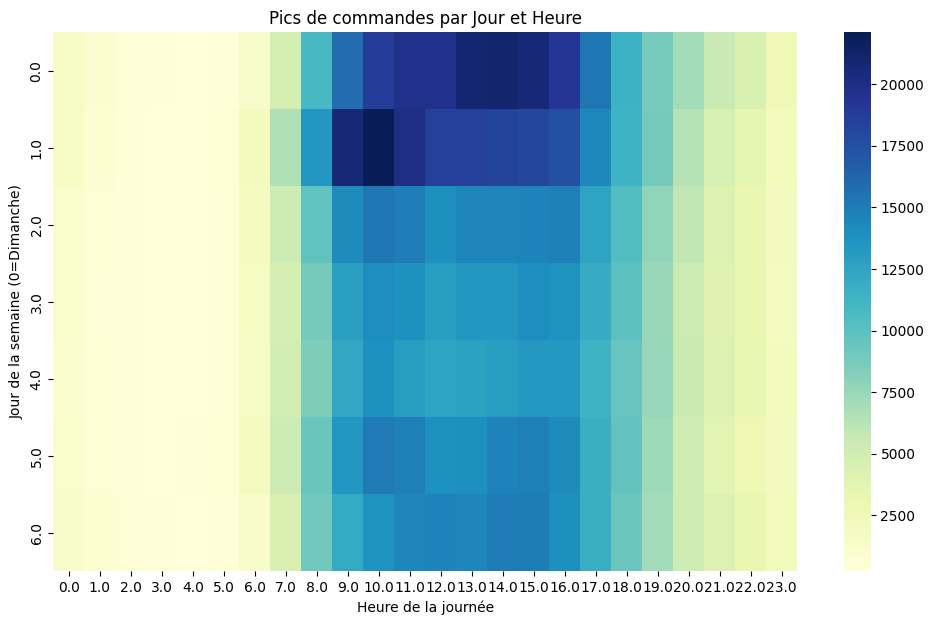

In [ ]:
df = pd.read_csv('df_clean.csv')

# Compte les commandes uniques par jour et par heure
heatmap_data = df.pivot_table(index='order_dow', 
                              columns='order_hour_of_day', 
                              values='order_id', 
                              aggfunc='nunique')

# Création Heatmap
plt.figure(figsize=(12, 7))
sns.heatmap(heatmap_data, cmap="YlGnBu")

plt.title('Pics de commandes par Jour et Heure')
plt.xlabel('Heure de la journée')
plt.ylabel('Jour de la semaine (0=Dimanche)')
plt.show()

    analyse

Le graphique de chaleur montre la répartition des commandes selon le jour de la semaine et l'heure de la journée, et on observe que les pics d’activité les plus intenses se situent le dimanche (jour 0) et le lundi (jour 1), particulièrement entre 9h et 16h. À l'inverse, les soirées (après 20h) et les nuits (avant 7h du matin) présentent une activité très faible. On remarque également que le reste de la semaine (mardi à samedi) conserve un flux constant durant la journée, mais avec une densité nettement moins élevée que lors du début de semaine. Cela indique que la majorité des clients planifient leurs courses principales pour la semaine à venir durant le week-end ou dès le lundi matin.

    réponse business

D’un point de vue business, l’entreprise devrait optimiser sa logistique et sa masse salariale pour répondre à cette forte concentration de commandes le dimanche et le lundi. Il serait judicieux de prévoir un renforcement des équipes de préparation de commandes et des créneaux de livraison durant ces fenêtres critiques pour garantir la satisfaction client et éviter les retards. En parallèle, pour lisser l'activité sur le reste de la semaine et maximiser l'utilisation des ressources, NEXTBUY pourrait lancer des offres promotionnelles spécifiques (ex: "Mardi Malin") ou réduire les frais de livraison les jours de faible affluence. Enfin, les périodes creuses de la nuit constituent le moment idéal pour effectuer la maintenance technique de l'application ou la mise à jour des stocks sans impacter l'expérience utilisateur.

## Comment les clients passent-ils commande ?


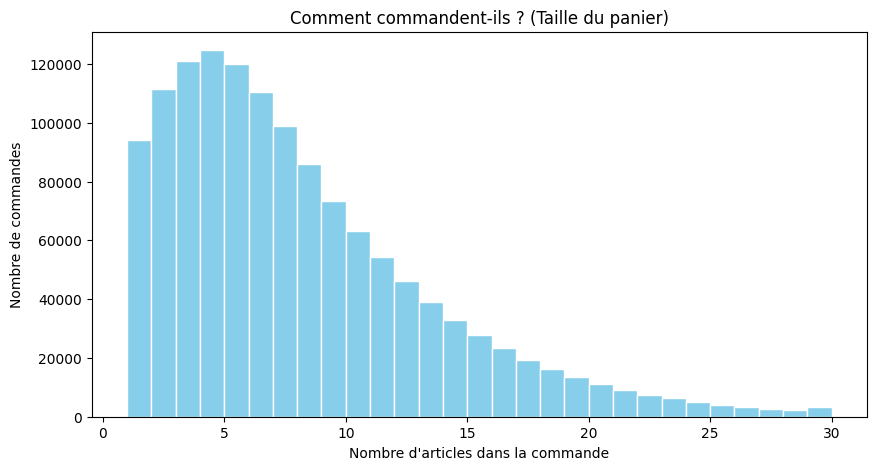

In [ ]:
# Compte le nombre d'articles par commande
taille_panier = df.groupby('order_id')['product_name'].count()

# Limité à 30 articles pour la lisibilité
plt.figure(figsize=(10, 5))
taille_panier.hist(bins=range(1, 31), color='skyblue', edgecolor='white', grid=False)

plt.title('Comment les clients passent-ils commande ? (Taille du panier)')
plt.xlabel('Nombre d\'articles dans la commande')
plt.ylabel('Nombre de commandes')
plt.show()

    analyse

Le graphique montre la distribution du nombre d'articles par commande, et on observe que la grande majorité des clients passent des petites commandes, avec un pic très marqué situé entre 4 et 6 articles par panier. Au-delà de 10 articles, le nombre de commandes diminue progressivement, ce qui indique que les gros paniers de plus de 20 articles sont relativement rares. Cela suggère que NEXTBUY est principalement utilisé pour des achats d'appoint, de dépannage ou des listes de courses très ciblées plutôt que pour de très grosses provisions mensuelles.

    réponse business

D’un point de vue business, l’entreprise devrait chercher à augmenter la valeur moyenne des commandes (AOV) pour rentabiliser les coûts fixes de livraison. Il serait intéressant de mettre en place des incitatifs comme la livraison gratuite à partir de 10 ou 12 articles, afin de pousser les clients situés dans la zone des 5 articles à doubler leur panier. En parallèle, puisque le flux est massif sur les petits paniers, NEXTBUY pourrait optimiser son interface de "checkout" pour rendre l'achat rapide encore plus fluide, ou proposer des suggestions de produits "oubliés" juste avant le paiement pour tenter d'ajouter un 6ème ou 7ème article au panier au dernier moment.

## Les clients achètent-ils plus de nourriture pour chats le matin que pour chiens le soir ?


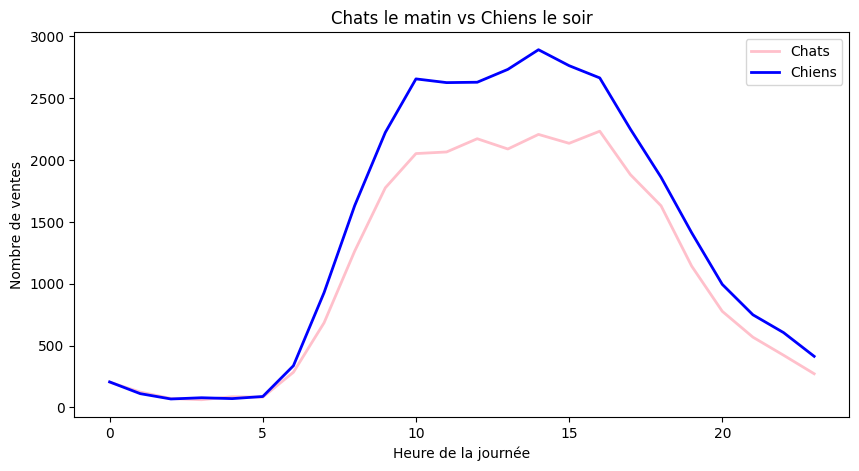

In [28]:
# Sépare les chats et les chiens
chats = df[df['product_name'].str.contains('Cat', case=False, na=False)]
chiens = df[df['product_name'].str.contains('Dog', case=False, na=False)]

# Compte les ventes par heure
heures_chats = chats.groupby('order_hour_of_day')['order_id'].count()
heures_chiens = chiens.groupby('order_hour_of_day')['order_id'].count()

plt.figure(figsize=(10, 5))
heures_chats.plot(label='Chats', color='pink', lw=2)
heures_chiens.plot(label='Chiens', color='blue', lw=2)

plt.title('Chats le matin vs Chiens le soir')
plt.xlabel('Heure de la journée')
plt.ylabel('Nombre de ventes')
plt.legend()
plt.show()

    analyse

Le graphique montre l'évolution des ventes de nourriture pour chats et pour chiens au fil de la journée, et on observe que les deux courbes suivent une tendance presque identique, avec un pic de commandes situé entre 10h et 16h. Contrairement à l'hypothèse de départ, il n'y a pas de distinction marquée entre les achats pour chats le matin et pour chiens le soir : les propriétaires d'animaux effectuent leurs achats globalement aux mêmes heures de pointe que les autres clients. On remarque toutefois que le volume de produits pour chiens (courbe bleue) est systématiquement supérieur à celui pour chats tout au long de la journée, ce qui indique une base de clients "propriétaires de chiens" plus importante ou des achats plus fréquents pour cette catégorie.

    réponse business

D’un point de vue business, l’entreprise devrait traiter la catégorie "Animaux de compagnie" comme un bloc homogène pour ses campagnes publicitaires généralistes, puisque les habitudes horaires ne varient pas selon l'animal. Cependant, étant donné que les produits pour chiens génèrent un volume de ventes plus élevé, NEXTBUY pourrait négocier de meilleurs tarifs de gros ou des exclusivités avec les fournisseurs de marques canines pour maximiser ses marges. En parallèle, pour dynamiser la courbe des produits pour chats qui est en retrait, l'entreprise pourrait tester des offres groupées (bundles) ou des recommandations personnalisées basées sur l'historique d'achat afin d'augmenter la part de marché sur ce segment spécifique.

## Quels produits faut-il mettre en avant le samedi ?


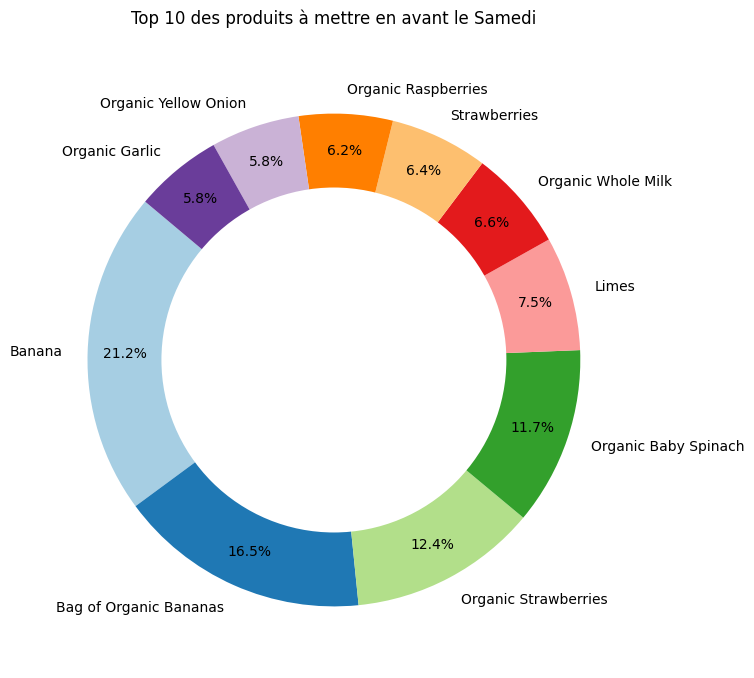

In [29]:
# Filtrer pour le samedi (order_dow == 6) et prendre le top 10
samedi_top = df[df['order_dow'] == 6]['product_name'].value_counts().head(10)

plt.figure(figsize=(8, 8))
plt.pie(samedi_top, labels=samedi_top.index, autopct='%1.1f%%', 
        startangle=140, pctdistance=0.85, colors=plt.cm.Paired.colors)

# Créer le cercle au centre pour faire l'effet "Donut"
centre_cercle = plt.Circle((0,0), 0.70, fc='white')
fig = plt.gcf()
fig.gca().add_artist(centre_cercle)

plt.title('Top 10 des produits à mettre en avant le Samedi', pad=20)
plt.show()

    analyse

Le graphique en anneau montre les 10 produits les plus commandés le samedi, et on observe que les bananes (classiques et bio) dominent largement le classement, représentant à elles seules plus de 37 % des ventes du top 10. On remarque également une très forte présence de produits frais et périssables, tels que les fraises (organiques et classiques), les épinards, le lait entier et les citrons verts. Cette concentration montre que le samedi est une journée stratégique pour le réapprovisionnement en produits de base frais, probablement en prévision des repas du week-end et de la semaine suivante.

    réponse business

D’un point de vue business, l’entreprise devrait s’assurer que les stocks de ces "best-sellers" sont au maximum dès le vendredi soir pour éviter toute rupture de stock le samedi, jour de forte affluence. Puisque les bananes sont le produit phare, elles peuvent servir de levier pour des ventes croisées : par exemple, proposer des promotions sur des céréales ou des produits de pâtisserie le samedi pourrait inciter les acheteurs de bananes et de lait à compléter leur panier. En parallèle, la présence importante de produits "Organic" le samedi confirme que les clients du week-end sont prêts à investir dans des produits de qualité supérieure, ce qui justifierait la mise en avant de têtes de gondoles virtuelles dédiées au "Petit-déjeuner sain" ou au "Marché frais" sur l'application ce jour-là.

## 💡 Recommandations et liens


  Quels produits ont la plus forte probabilité d'être rachetés ?

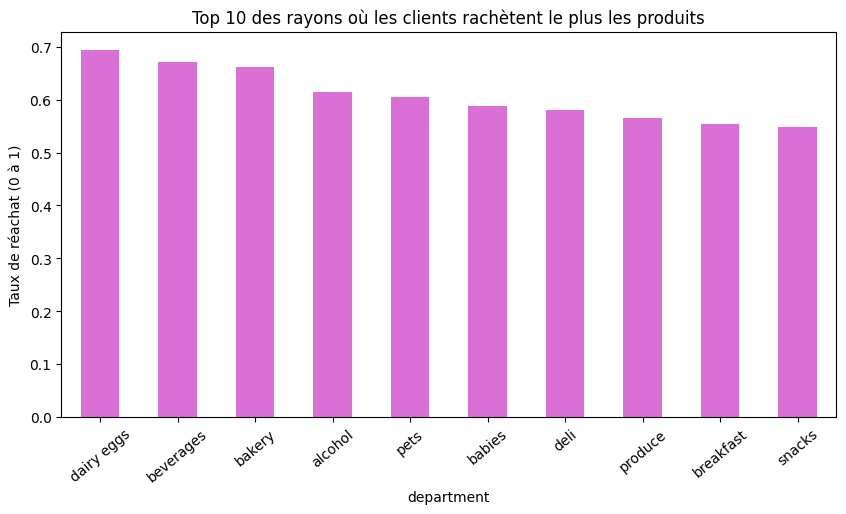

In [ ]:
# Calcule le taux de réachat par rayon
reorder_r = df_clean.groupby('department')['reordered'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
reorder_r.plot(kind='bar', color='orchid')
plt.title('Top 10 des rayons où les clients rachètent le plus les produits')
plt.ylabel('Taux de réachat (0 à 1)')
plt.xticks(rotation=40) 
plt.show()

    analyse

Le graphique en barres montre les 10 départements ayant la plus forte probabilité de réachat, et on observe que les produits laitiers et les œufs (dairy eggs) arrivent en tête avec un taux proche de 70 %, suivis de près par les boissons (beverages) et la boulangerie (bakery). On remarque également que des catégories comme les produits pour animaux (pets) et pour bébés (babies) affichent des taux de réachat très élevés, dépassant les 60 %. Cela indique que ces départements constituent le cœur de la fidélité client de NEXTBUY : une fois qu'un client commence à acheter ces produits, il a de très fortes chances de les commander à nouveau lors de ses prochaines sessions.

    réponse business

D’un point de vue business, l’entreprise devrait considérer ces départements comme des piliers de rétention. Puisque les clients rachètent systématiquement ces articles, il est crucial de s'assurer qu'ils ne soient jamais en rupture de stock, car une indisponibilité sur ces produits pourrait pousser le client à faire l'intégralité de sa commande chez un concurrent. NEXTBUY pourrait également utiliser ces produits à fort taux de réachat pour mettre en place des programmes de réapprovisionnement automatique ou des abonnements, simplifiant ainsi le parcours d'achat. Enfin, pour les départements situés en fin de classement comme les snacks, l'entreprise pourrait tester des offres de découverte ou des coupons de réduction sur le premier achat afin de transformer ces produits occasionnels en nouvelles habitudes de consommation.